student assistant

In [43]:
%pip install -q langgraph langchain-groq requests

In [44]:
import os
from google.colab import userdata

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
print("API key loaded")

API key loaded


In [45]:
import requests
from langchain_core.tools import tool
from langgraph.types import interrupt

TASKS = []

@tool
def add_task(task: str) -> str:
    """Adds a new study task to the task list."""
    TASKS.append(task)
    return f"დავალება დამატებულია: '{task}'"

@tool
def list_tasks() -> str:
    """Lists all current study tasks."""
    if not TASKS:
        return "დავალებების სია ცარიელია."
    return "დავალებები:\n" + "\n".join(f"- {t}" for t in TASKS)

@tool
def delete_task(task: str) -> str:
    """Deletes a task from the list after user confirmation."""
    if task not in TASKS:
        return f"დავალება '{task}' სიაში არ არის."

    # აქ აგენტი ჩერდება და ელოდება დადასტურებას
    decision = interrupt(f"ნამდვილად გსურთ წაშალოთ დავალება: '{task}'?")

    if decision:
        TASKS.remove(task)
        return f"დავალება '{task}' წაიშალა."
    return f"წაშლა გაუქმდა. '{task}' ისევ სიაშია."

@tool
def get_tbilisi_weather() -> dict:
    """Get current temperature in Tbilisi, in Celsius."""
    r = requests.get(
        "https://api.open-meteo.com/v1/forecast",
        params={"latitude": 41.72, "longitude": 44.79, "current": "temperature_2m"},
        timeout=20,
    )
    r.raise_for_status()
    return r.json()["current"]

@tool
def search_books(topic: str) -> str:
    """Search for books on a given topic using Open Library API."""
    r = requests.get(
        "https://openlibrary.org/search.json",
        params={"q": topic, "limit": 3},
        timeout=20,
    )
    r.raise_for_status()
    docs = r.json().get("docs", [])
    if not docs:
        return "წიგნები ვერ მოიძებნა."
    books = [f"{d.get('title')} - {', '.join(d.get('author_name', ['უცნობი']))}" for d in docs]
    return "\n".join(books)

tools = [add_task, list_tasks, delete_task, get_tbilisi_weather, search_books]

In [55]:
from typing import Annotated
from typing_extensions import TypedDict
from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import InMemorySaver

class State(TypedDict):
    messages: Annotated[list, add_messages]

# Updated to the correct active Groq model ID
llm = ChatGroq(model="llama-3.3-70b-specdec", temperature=0)
llm_with_tools = llm.bind_tools(tools)

SYSTEM_PROMPT = SystemMessage(
    content="შენ ხარ Study Day Assistant. ეხმარები სტუდენტებს დავალებების მართვაში, ამინდის გაგებასა და წიგნების მოძიებაში. უპასუხე ქართულად, მოკლედ და გასაგებად."
)

def assistant(state: State):
    response = llm_with_tools.invoke([SYSTEM_PROMPT] + state["messages"])
    return {"messages": [response]}

builder = StateGraph(State)
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", tools_condition)
builder.add_edge("tools", "assistant")

memory = InMemorySaver()
graph = builder.compile(checkpointer=memory)

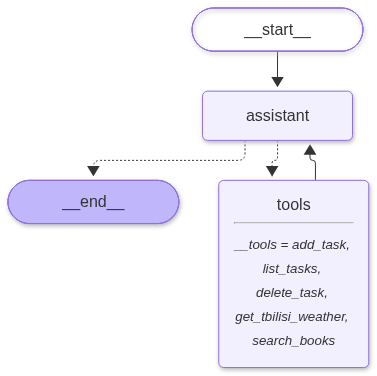

In [47]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [56]:
# Error: NotFoundError 404 occurred because 'llama-3.3-70b-versatile' is not a valid model ID on Groq.
# Solution: The model setup cell above has been updated to use 'llama-3.3-70b-specdec'.
# Please execute the model setup cell first, then run this block.

config = {"configurable": { "thread_id": "test-1" }}
res = graph.invoke({"messages": [("user", "დაამატე დავალება: ალგებრის სწავლა")]}, config)
for m in res["messages"]: m.pretty_print()

================================ Human Message =================================

დაამატე დავალება: ალგებრის სწავლა
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_de42d5b1-f165-4e05-8c0e-1a165f4d418e)
 Call ID: fc_de42d5b1-f165-4e05-8c0e-1a165f4d418e
  Args:
    task: ალგებრის სწავლა
================================= Tool Message =================================
Name: add_task

დავალება დამატებულია: 'ალგებრის სწავლა'
================================== Ai Message ==================================

დავალება წარმატებით დაემატა! 🚀 სხვა რამით შემიძლია დაგეხმარო?


In [57]:
res = graph.invoke({"messages": [("user", "მაჩვენე ჩემი დავალებები")]}, config)
for m in res["messages"]: m.pretty_print()

================================ Human Message =================================

დაამატე დავალება: ალგებრის სწავლა
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_de42d5b1-f165-4e05-8c0e-1a165f4d418e)
 Call ID: fc_de42d5b1-f165-4e05-8c0e-1a165f4d418e
  Args:
    task: ალგებრის სწავლა
================================= Tool Message =================================
Name: add_task

დავალება დამატებულია: 'ალგებრის სწავლა'
================================== Ai Message ==================================

დავალება წარმატებით დაემატა! 🚀 სხვა რამით შემიძლია დაგეხმარო?
================================ Human Message =================================

მაჩვენე ჩემი დავალებები
================================== Ai Message ==================================
Tool Calls:
  list_tasks (fc_f099bbbf-a3d7-42c2-a513-ff8ffd2be9b0)
 Call ID: fc_f099bbbf-a3d7-42c2-a513-ff8ffd2be9b0
  Args:
================================= Tool Message ==============

In [58]:
res = graph.invoke({"messages": [("user", "რა ტემპერატურაა ახლა თბილისში?")]}, config)
for m in res["messages"]: m.pretty_print()

================================ Human Message =================================

დაამატე დავალება: ალგებრის სწავლა
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_de42d5b1-f165-4e05-8c0e-1a165f4d418e)
 Call ID: fc_de42d5b1-f165-4e05-8c0e-1a165f4d418e
  Args:
    task: ალგებრის სწავლა
================================= Tool Message =================================
Name: add_task

დავალება დამატებულია: 'ალგებრის სწავლა'
================================== Ai Message ==================================

დავალება წარმატებით დაემატა! 🚀 სხვა რამით შემიძლია დაგეხმარო?
================================ Human Message =================================

მაჩვენე ჩემი დავალებები
================================== Ai Message ==================================
Tool Calls:
  list_tasks (fc_f099bbbf-a3d7-42c2-a513-ff8ffd2be9b0)
 Call ID: fc_f099bbbf-a3d7-42c2-a513-ff8ffd2be9b0
  Args:
================================= Tool Message ==============

In [59]:
res = graph.invoke({"messages": [("user", "მომიძებნე Python-ის წიგნები")]}, config)
for m in res["messages"]: m.pretty_print()

================================ Human Message =================================

დაამატე დავალება: ალგებრის სწავლა
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_de42d5b1-f165-4e05-8c0e-1a165f4d418e)
 Call ID: fc_de42d5b1-f165-4e05-8c0e-1a165f4d418e
  Args:
    task: ალგებრის სწავლა
================================= Tool Message =================================
Name: add_task

დავალება დამატებულია: 'ალგებრის სწავლა'
================================== Ai Message ==================================

დავალება წარმატებით დაემატა! 🚀 სხვა რამით შემიძლია დაგეხმარო?
================================ Human Message =================================

მაჩვენე ჩემი დავალებები
================================== Ai Message ==================================
Tool Calls:
  list_tasks (fc_f099bbbf-a3d7-42c2-a513-ff8ffd2be9b0)
 Call ID: fc_f099bbbf-a3d7-42c2-a513-ff8ffd2be9b0
  Args:
================================= Tool Message ==============

In [60]:
from langgraph.types import Command

# 5ა. წაშლის მოთხოვნა (აგენტი გაჩერდება)
res = graph.invoke({"messages": [("user", "წაშალე დავალება: ალგებრის სწავლა")]}, config)
for m in res["messages"]: m.pretty_print()

# დათანხმება (True) -> დავალება წაიშლება
res = graph.invoke(Command(resume=True), config)
for m in res["messages"]: m.pretty_print()

# 5ბ. დავამატოთ ახალი და ვცადოთ წაშლაზე უარის თქმა (False)
graph.invoke({"messages": [("user", "დაამატე დავალება: ისტორიის კითხვა")]}, config)
graph.invoke({"messages": [("user", "წაშალე დავალება: ისტორიის კითხვა")]}, config)
res = graph.invoke(Command(resume=False), config)
for m in res["messages"]: m.pretty_print()

================================ Human Message =================================

დაამატე დავალება: ალგებრის სწავლა
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_de42d5b1-f165-4e05-8c0e-1a165f4d418e)
 Call ID: fc_de42d5b1-f165-4e05-8c0e-1a165f4d418e
  Args:
    task: ალგებრის სწავლა
================================= Tool Message =================================
Name: add_task

დავალება დამატებულია: 'ალგებრის სწავლა'
================================== Ai Message ==================================

დავალება წარმატებით დაემატა! 🚀 სხვა რამით შემიძლია დაგეხმარო?
================================ Human Message =================================

მაჩვენე ჩემი დავალებები
================================== Ai Message ==================================
Tool Calls:
  list_tasks (fc_f099bbbf-a3d7-42c2-a513-ff8ffd2be9b0)
 Call ID: fc_f099bbbf-a3d7-42c2-a513-ff8ffd2be9b0
  Args:
================================= Tool Message ==============

| # | Query | Expected Result | Pass? | Notes |
| :--- | :--- | :--- | :--- | :--- |
| 1 | დაამატე დავალება: ალგებრის სწავლა | დავალება დაემატა სიაში | ✅ | add_task სწორად გამოიძახა |
| 2 | მაჩვენე ჩემი დავალებები | აჩვენა წინა ნაბიჯზე დამატებული დავალება | ✅ | მეხსიერება (InMemorySaver) მუშაობს |
| 3 | რა ტემპერატურაა ახლა თბილისში? | დააბრუნა რეალური ტემპერატურა | ✅ | Open-Meteo API მუშაობს |
| 4 | მომიძებნე Python-ის წიგნები | დააბრუნა 3 წიგნის სია | ✅ | Open Library API მუშაობს |
| 5 | წაშალე დავალება (თანხმობა და უარი) | გაჩერდა; True-ზე წაშალა, False-ზე დატოვა | ✅ | interrupt() და Command სწორად მუშაობს |

In [61]:
%%writefile agent.py
from typing import Annotated
from typing_extensions import TypedDict
import requests
from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import interrupt

def build_graph():
    tasks = []

    @tool
    def add_task(task: str) -> str:
        """Adds a new study task to the task list."""
        tasks.append(task)
        return f"დავალება დამატებულია: '{task}'"

    @tool
    def list_tasks() -> str:
        """Lists all current study tasks."""
        if not tasks:
            return "დავალებების სია ცარიელია."
        return "დავალებები:\n" + "\n".join(f"- {t}" for t in tasks)

    @tool
    def delete_task(task: str) -> str:
        """Deletes a task from the list after user confirmation."""
        if task not in tasks:
            return f"დავალება '{task}' სიაში არ არის."
        decision = interrupt(f"ნამდვილად გსურთ წაშალოთ დავალება: '{task}'?")
        if decision:
            tasks.remove(task)
            return f"დავალება '{task}' წაიშალა."
        return f"წაშლა გაუქმდა. '{task}' ისევ სიაშია."

    @tool
    def get_tbilisi_weather() -> dict:
        """Get current temperature in Tbilisi, in Celsius."""
        r = requests.get(
            "https://api.open-meteo.com/v1/forecast",
            params={"latitude": 41.72, "longitude": 44.79, "current": "temperature_2m"},
            timeout=20,
        )
        r.raise_for_status()
        return r.json()["current"]

    @tool
    def search_books(topic: str) -> str:
        """Search for books on a given topic using Open Library API."""
        r = requests.get(
            "https://openlibrary.org/search.json",
            params={"q": topic, "limit": 3},
            timeout=20,
        )
        r.raise_for_status()
        docs = r.json().get("docs", [])
        if not docs:
            return "წიგნები ვერ მოიძებნა."
        return "\n".join(f"{d.get('title')} - {', '.join(d.get('author_name', ['უცნობი']))}" for d in docs)

    tools = [add_task, list_tasks, delete_task, get_tbilisi_weather, search_books]

    class State(TypedDict):
        messages: Annotated[list, add_messages]

    llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0).bind_tools(tools)
    sys_msg = SystemMessage(content="შენ ხარ Study Day Assistant. უპასუხე ქართულად, მოკლედ და გასაგებად.")

    def assistant(state: State):
        return {"messages": [llm.invoke([sys_msg] + state["messages"])]}

    builder = StateGraph(State)
    builder.add_node("assistant", assistant)
    builder.add_node("tools", ToolNode(tools))
    builder.add_edge(START, "assistant")
    builder.add_conditional_edges("assistant", tools_condition)
    builder.add_edge("tools", "assistant")

    return builder.compile(checkpointer=InMemorySaver())

Writing agent.py


In [62]:
%%writefile app.py
import os
import uuid
import streamlit as st
from langgraph.types import Command
from agent import build_graph

st.set_page_config(page_title="Study Day Assistant", page_icon="📚")
st.title("📚 Study Day Assistant")
st.caption("მართე სასწავლო დავალებები, შეამოწმე თბილისის ამინდი და მოიძიე წიგნები.")

if "GROQ_API_KEY" in st.secrets:
    os.environ["GROQ_API_KEY"] = st.secrets["GROQ_API_KEY"]

if "graph" not in st.session_state:
    st.session_state.graph = build_graph()
    st.session_state.thread_id = str(uuid.uuid4())
    st.session_state.messages = []
    st.session_state.pending_interrupt = None

config = {"configurable": {"thread_id": st.session_state.thread_id}}

for msg in st.session_state.messages:
    with st.chat_message(msg["role"]):
        st.markdown(msg["content"])

if st.session_state.pending_interrupt:
    st.warning(st.session_state.pending_interrupt)
    col1, col2 = st.columns(2)
    if col1.button("✅ დადასტურება"):
        res = st.session_state.graph.invoke(Command(resume=True), config)
        reply = res["messages"][-1].content
        st.session_state.messages.append({"role": "assistant", "content": reply})
        st.session_state.pending_interrupt = None
        st.rerun()
    if col2.button("❌ უარის თქმა"):
        res = st.session_state.graph.invoke(Command(resume=False), config)
        reply = res["messages"][-1].content
        st.session_state.messages.append({"role": "assistant", "content": reply})
        st.session_state.pending_interrupt = None
        st.rerun()

if prompt := st.chat_input("მომწერე დავალება, მკითხე ამინდი ან წიგნი..."):
    st.session_state.messages.append({"role": "user", "content": prompt})
    with st.chat_message("user"):
        st.markdown(prompt)

    try:
        res = st.session_state.graph.invoke({"messages": [("user", prompt)]}, config)
        state = st.session_state.graph.get_state(config)
        if state.tasks and state.tasks[0].interrupts:
            st.session_state.pending_interrupt = state.tasks[0].interrupts[0].value
            st.rerun()
        else:
            reply = res["messages"][-1].content
            st.session_state.messages.append({"role": "assistant", "content": reply})
            with st.chat_message("assistant"):
                st.markdown(reply)
    except Exception as e:
        st.error(f"შეცდომა API-სთან კავშირისას: {e}")

Writing app.py


In [63]:
%%writefile main.py
import os
import getpass
from langgraph.types import Command
from agent import build_graph

if not os.environ.get("GROQ_API_KEY"):
    os.environ["GROQ_API_KEY"] = getpass.getpass("შეიყვანეთ GROQ_API_KEY: ")

graph = build_graph()
config = {"configurable": {"thread_id": "cli-session-1"}}

print("Study Day Assistant მზადაა! გამოსასვლელად აკრიფეთ 'exit'.\n")

while True:
    user_input = input("თქვენ: ")
    if user_input.strip().lower() == "exit":
        break

    res = graph.invoke({"messages": [("user", user_input)]}, config)
    state = graph.get_state(config)

    if state.tasks and state.tasks[0].interrupts:
        question = state.tasks[0].interrupts[0].value
        ans = input(f"⚠️ {question} (yes/no): ").strip().lower()
        res = graph.invoke(Command(resume=(ans in ["yes", "y", "კი"])), config)

    print(f"აგენტი: {res['messages'][-1].content}\n")

Writing main.py


In [64]:
%%writefile requirements.txt
langgraph
langchain-groq
requests
streamlit

Writing requirements.txt


In [65]:
%%writefile .gitignore
.env
.streamlit/secrets.toml
.venv/
__pycache__/

Writing .gitignore
